# Tanimoto similarity to seed 

In [2]:
#!pip install rdkit pandas numpy matplotlib seaborn

## functions

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import AllChem
import seaborn as sns
import scipy.stats  # Added for statistical testing

def calculate_tanimoto_similarities(smiles_list, seed_smiles):
    """
    Calculate Tanimoto similarity between a seed SMILES and a list of SMILES strings.
    
    Parameters:
    -----------
    smiles_list : list
        List of SMILES strings to compare against the seed
    seed_smiles : str
        Seed SMILES string to compare against
        
    Returns:
    --------
    list
        List of Tanimoto similarity scores
    """
    # Convert seed SMILES to RDKit molecule
    seed_mol = Chem.MolFromSmiles(seed_smiles)
    if seed_mol is None:
        raise ValueError(f"Invalid seed SMILES: {seed_smiles}")
    
    # Generate fingerprint for seed molecule using the updated method
    fpgen = AllChem.GetMorganGenerator(radius=2, fpSize=2048)
    seed_fp = fpgen.GetFingerprint(seed_mol)
    
    similarities = []
    valid_count = 0
    invalid_count = 0
    
    # Calculate similarity for each SMILES in the list
    for smiles in smiles_list:
        try:
            mol = Chem.MolFromSmiles(smiles)
            if mol is None:
                invalid_count += 1
                continue
                
            # Use the same fingerprint generator for consistency
            mol_fp = fpgen.GetFingerprint(mol)
            similarity = DataStructs.TanimotoSimilarity(seed_fp, mol_fp)
            similarities.append(similarity)
            valid_count += 1
        except Exception as e:
            invalid_count += 1
            print(f"Error processing SMILES {smiles}: {e}")
    
    print(f"Processed {valid_count} valid SMILES and encountered {invalid_count} invalid ones")
    return similarities

def plot_similarity_histogram(similarities, output_file=None, title='Tanimoto Similarity'):
    """
    Create a histogram of Tanimoto similarities with buckets
    
    Parameters:
    -----------
    similarities : list
        List of Tanimoto similarity scores
    output_file : str, optional
        Path to save the plot (if None, plot is displayed)
    """
    # Set style
    sns.set(style="whitegrid")
    plt.figure(figsize=(4, 5))
    
    # Create histogram
    bins = np.arange(0, 1.1, 0.1)  # 0.0-0.1, 0.1-0.2, ..., 0.9-1.0
    
    # Plot histogram
    n, bins, patches = plt.hist(similarities, bins=bins, alpha=0.7, color='skyblue', edgecolor='black')
    
    # Customize colors based on similarity value
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    cm = plt.cm.get_cmap('viridis')
    for patch, center in zip(patches, bin_centers):
        color = cm(center)
        patch.set_facecolor(color)
    
    # Add count labels on top of each bar
    for i, count in enumerate(n):
        plt.text(bin_centers[i], count + max(n)*0.01, f"{int(count)}", 
                 ha='center', va='bottom', ) #fontweight='bold'
    
    # Calculate percentages for each bucket
    bucket_counts = {}
    for threshold in [0.9, 0.8, 0.7, 0.6, 0.5]:
        count = sum(1 for sim in similarities if sim >= threshold)
        percentage = (count / len(similarities)) * 100
        bucket_counts[threshold] = (count, percentage)
    
    # Add text box with bucket statistics
    stats_text = "Similarity Statistics:\n"
    stats_text += "\n".join([f"≥ {threshold:.1f}: {count} ({percentage:.1f}%)" 
                            for threshold, (count, percentage) in bucket_counts.items()])
    
    plt.annotate(stats_text, xy=(0.72, 0.6), xycoords='axes fraction',
                 bbox=dict(boxstyle="round,pad=0.5", facecolor='white', alpha=0.8))
    
    # Add labels and title
    plt.xlabel(title, fontsize=10)
    plt.ylabel('Count', fontsize=9)
    #plt.title('Distribution of Tanimoto Similarities', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # Add vertical lines at important thresholds
    #for threshold in [0.9, 0.8, 0.7]:
    #    plt.axvline(x=threshold, color='red', linestyle='--', alpha=0.6)
    #    plt.text(threshold+0.01, max(n)*0.9, f'Threshold: {threshold}', 
    #            rotation=90, color='red', va='top')
    
    plt.tight_layout()
    
    # Save or show plot
    if output_file:
        plt.savefig(output_file, dpi=300, bbox_inches='tight')
        print(f"Plot saved to {output_file}")
    else:
        plt.show()

def compare_datasets_boxplot(similarities_1, similarities_2, dataset_names=None, output_file=None, prt_table=False, prt_treshh=False):
    """
    Create a boxplot comparing two datasets of Tanimoto similarities against the same seed
    
    Parameters:
    -----------
    similarities_1 : list
        List of Tanimoto similarity scores for first dataset
    similarities_2 : list
        List of Tanimoto similarity scores for second dataset
    dataset_names : list, optional
        Names for the two datasets (default: ['Dataset 1', 'Dataset 2'])
    output_file : str, optional
        Path to save the plot (if None, plot is displayed)
    """
    if dataset_names is None:
        dataset_names = ['Dataset 1', 'Dataset 2']
    
    # Set style
    sns.set(style="whitegrid")
    plt.figure(figsize=(10, 8))
    
    # Prepare data for boxplot
    data = []
    labels = []
    
    for sim in similarities_1:
        data.append(sim)
        labels.append(dataset_names[0])
    
    for sim in similarities_2:
        data.append(sim)
        labels.append(dataset_names[1])
    
    df = pd.DataFrame({
        'Similarity': data,
        'Dataset': labels
    })
    
    # Create boxplot
    ax = sns.boxplot(x='Dataset', y='Similarity', data=df, palette='Set2')
    
    # Add individual points with jitter for better visualization
    sns.stripplot(x='Dataset', y='Similarity', data=df, 
                 size=4, color='0.3', alpha=0.4, jitter=True)
    
    # Add statistics table
    stats_text = "Similarity Statistics:\n\n"

    if prt_table == True:
        for i, (dataset_name, similarities) in enumerate(zip(dataset_names, [similarities_1, similarities_2])):
            stats_text += f"{dataset_name}:\n"
            stats_text += f"  Count: {len(similarities)}\n"
            stats_text += f"  Mean: {np.mean(similarities):.3f}\n"
            stats_text += f"  Median: {np.median(similarities):.3f}\n"
            stats_text += f"  Min: {min(similarities):.3f}\n"
            stats_text += f"  Max: {max(similarities):.3f}\n"
            
            for threshold in [0.9, 0.8, 0.7]:
                count = sum(1 for sim in similarities if sim >= threshold)
                percentage = (count / len(similarities)) * 100
                stats_text += f"  ≥ {threshold:.1f}: {count} ({percentage:.1f}%)\n"
            
            if i == 0:  # Add a newline between datasets
                stats_text += "\n"
        
    if prt_treshh == True:
        # Calculate Mann-Whitney U test for statistical significance
        u_stat, p_value = scipy.stats.mannwhitneyu(similarities_1, similarities_2, alternative='two-sided')
        stats_text += f"\nMann-Whitney U Test:\n"
        stats_text += f"  p-value: {p_value:.4f}\n"
        stats_text += f"  Statistically different: {'Yes' if p_value < 0.05 else 'No'}"
        
        plt.annotate(stats_text, xy=(0.02, 0.98), xycoords='figure fraction',
                     va='top', ha='left',
                     bbox=dict(boxstyle="round,pad=0.5", facecolor='white', alpha=0.8))

    
        # Add horizontal lines at important thresholds
        for threshold in [0.9, 0.8, 0.7]:
            ax.axhline(y=threshold, color='red', linestyle='--', alpha=0.6)
            plt.text(1.05, threshold, f'Threshold: {threshold}', 
                    color='red', va='center')
        
    # Add labels and title
    plt.xlabel('', fontsize=14)  # Empty x-label since dataset names are displayed
    plt.ylabel('Tanimoto Similarity', fontsize=14)
    plt.title('Comparison of Tanimoto Similarities Between Datasets', fontsize=16)

    plt.ylim(0.0,0.8)
    #plt.ylim(-0.05, 1.05)  # Limit y-axis to 0-1 with a small margin
    
    plt.tight_layout()
    
    # Save or show plot
    if output_file:
        plt.savefig(output_file, dpi=300, bbox_inches='tight')
        print(f"Plot saved to {output_file}")
    else:
        plt.show()


## Seed data

In [12]:
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"

# Replace with your seed SMILES
seed_smiles = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"  

input_file_1 = "../data/interim/molmim/guided/v2/BCS-CN20332_QSARAIH_b1.csv"
#input_file_2 = "../data/interim/molmim/guided/molmmim-Guided_BCS-CN20332_batch2_n100_QED.csv"


## main comparison

Loaded 66 SMILES strings
Processed 66 valid SMILES and encountered 0 invalid ones


/tmp/ipykernel_32633/1884670288.py:82: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cm = plt.cm.get_cmap('viridis')


Plot saved to tanimoto_similarity_histogram.png

Summary Statistics:
Total molecules: 66
Molecules with similarity ≥ 0.9: 0 (0.0%)
Molecules with similarity ≥ 0.8: 0 (0.0%)
Molecules with similarity ≥ 0.7: 0 (0.0%)
Molecules with similarity ≥ 0.6: 0 (0.0%)
Molecules with similarity ≥ 0.5: 2 (3.0%)


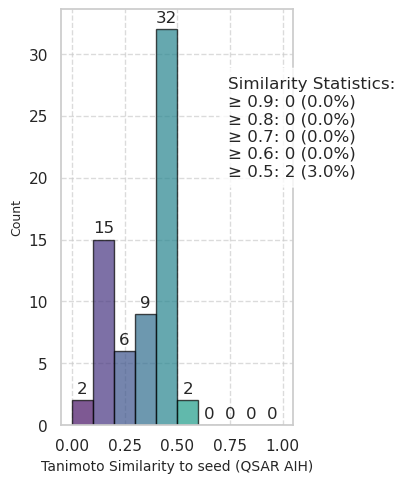

In [14]:
df = pd.read_csv(input_file_1, sep=";")


# Read SMILES from file
# Modify this part according to your file format
try:
    
    if 'SMILES' in df.columns:
        smiles_list = df['SMILES'].tolist()
    else:
        # Try to find a column that might contain SMILES
        potential_cols = [col for col in df.columns if any(s in col.lower() for s in ['smiles', 'smi', 'structure'])]
        if potential_cols:
            smiles_list = df[potential_cols[0]].tolist()
        else:
            # Assume first column contains SMILES
            smiles_list = df.iloc[:, 0].tolist()
except:
    # For text file with one SMILES per line
    with open(input_file, 'r') as f:
        smiles_list = [line.strip() for line in f if line.strip()]

print(f"Loaded {len(smiles_list)} SMILES strings")

# Calculate similarities
similarities = calculate_tanimoto_similarities(smiles_list, seed_smiles)

#set a title 
title = "Tanimoto Similarity to seed (QSAR AIH)"
# Create visualization
plot_similarity_histogram(similarities, output_file="tanimoto_similarity_histogram.png", title=title)

# Print summary statistics
print("\nSummary Statistics:")
print(f"Total molecules: {len(similarities)}")
for threshold in [0.9, 0.8, 0.7, 0.6, 0.5]:
    count = sum(1 for sim in similarities if sim >= threshold)
    percentage = (count / len(similarities)) * 100
    print(f"Molecules with similarity ≥ {threshold:.1f}: {count} ({percentage:.1f}%)")

Loaded 66 SMILES strings
Processed 66 valid SMILES and encountered 0 invalid ones


/tmp/ipykernel_19555/943369224.py:82: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cm = plt.cm.get_cmap('viridis')


Plot saved to tanimoto_similarity_histogram.png

Summary Statistics:
Total molecules: 66
Molecules with similarity ≥ 0.9: 0 (0.0%)
Molecules with similarity ≥ 0.8: 0 (0.0%)
Molecules with similarity ≥ 0.7: 0 (0.0%)
Molecules with similarity ≥ 0.6: 0 (0.0%)
Molecules with similarity ≥ 0.5: 0 (0.0%)


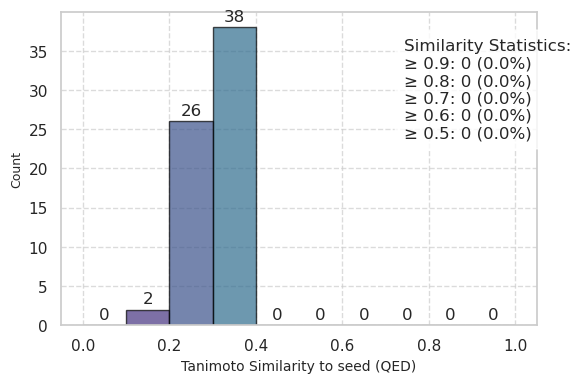

In [13]:
df = pd.read_csv(input_file_2, sep=";")

# Read SMILES from file
# Modify this part according to your file format
try:
    
    if 'SMILES' in df.columns:
        smiles_list = df['SMILES'].tolist()
    else:
        # Try to find a column that might contain SMILES
        potential_cols = [col for col in df.columns if any(s in col.lower() for s in ['smiles', 'smi', 'structure'])]
        if potential_cols:
            smiles_list = df[potential_cols[0]].tolist()
        else:
            # Assume first column contains SMILES
            smiles_list = df.iloc[:, 0].tolist()
except:
    # For text file with one SMILES per line
    with open(input_file, 'r') as f:
        smiles_list = [line.strip() for line in f if line.strip()]

print(f"Loaded {len(smiles_list)} SMILES strings")

# Calculate similarities
similarities = calculate_tanimoto_similarities(smiles_list, seed_smiles)

# Create visualization
plot_similarity_histogram(similarities, output_file="tanimoto_similarity_histogram.png", title=title)

# Print summary statistics
print("\nSummary Statistics:")
print(f"Total molecules: {len(similarities)}")
for threshold in [0.9, 0.8, 0.7, 0.6, 0.5]:
    count = sum(1 for sim in similarities if sim >= threshold)
    percentage = (count / len(similarities)) * 100
    print(f"Molecules with similarity ≥ {threshold:.1f}: {count} ({percentage:.1f}%)")

## compare two distributions

Loaded 100 SMILES strings from ../data/interim/molmim/unguided/molmmim_BCS-CN20332_QED_sim03_100p_100m.csv
Loaded 66 SMILES strings from ../data/interim/molmim/guided/molmmim-Guided_BCS-CN20332_batch2_n100_QED.csv
Processed 100 valid SMILES and encountered 0 invalid ones
Processed 66 valid SMILES and encountered 0 invalid ones


/tmp/ipykernel_19555/943369224.py:168: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='Dataset', y='Similarity', data=df, palette='Set2')


Plot saved to tanimoto_comparison_boxplot.png

Summary Statistics for molmim guided LogP:
Total molecules: 100
Molecules with similarity ≥ 0.9: 0 (0.0%)
Molecules with similarity ≥ 0.8: 0 (0.0%)
Molecules with similarity ≥ 0.7: 0 (0.0%)
Molecules with similarity ≥ 0.6: 0 (0.0%)
Molecules with similarity ≥ 0.5: 11 (11.0%)

Summary Statistics for molmim unguided LogP:
Total molecules: 66
Molecules with similarity ≥ 0.9: 0 (0.0%)
Molecules with similarity ≥ 0.8: 0 (0.0%)
Molecules with similarity ≥ 0.7: 0 (0.0%)
Molecules with similarity ≥ 0.6: 0 (0.0%)
Molecules with similarity ≥ 0.5: 0 (0.0%)


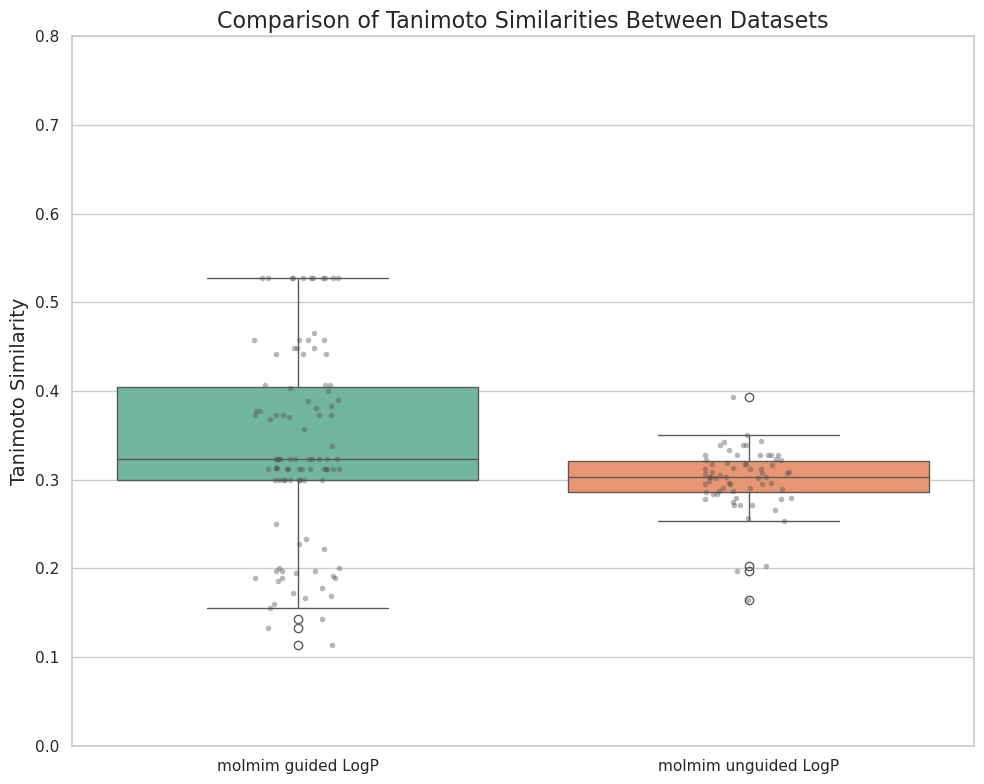

In [14]:
# Function to read SMILES from file
def read_smiles_from_file(input_file):
    try:
        # For CSV with a column named 'SMILES'
        df = pd.read_csv(input_file, sep=";")
        if 'SMILES' in df.columns:
            smiles_list = df['SMILES'].tolist()
        else:
            # Try to find a column that might contain SMILES
            potential_cols = [col for col in df.columns if any(s in col.lower() for s in ['smiles', 'smi', 'structure'])]
            if potential_cols:
                smiles_list = df[potential_cols[0]].tolist()
            else:
                # Assume first column contains SMILES
                smiles_list = df.iloc[:, 0].tolist()
    except:
        # For text file with one SMILES per line
        with open(input_file, 'r') as f:
            smiles_list = [line.strip() for line in f if line.strip()]
    
    print(f"Loaded {len(smiles_list)} SMILES strings from {input_file}")
    return smiles_list

# Read SMILES from both files
smiles_list_1 = read_smiles_from_file(input_file_1)
smiles_list_2 = read_smiles_from_file(input_file_2)

# Calculate similarities for both datasets
similarities_1 = calculate_tanimoto_similarities(smiles_list_1, seed_smiles)
similarities_2 = calculate_tanimoto_similarities(smiles_list_2, seed_smiles)

# Create histogram for first dataset
#plot_similarity_histogram(similarities_1, output_file="dataset1_tanimoto_histogram.png")

# Create histogram for second dataset
#plot_similarity_histogram(similarities_2, output_file="dataset2_tanimoto_histogram.png")

# Create comparative boxplot
dataset_names = ["molmim guided LogP", "molmim unguided LogP"]  # Customize these names
compare_datasets_boxplot(similarities_1, similarities_2, dataset_names, 
                        output_file="tanimoto_comparison_boxplot.png")

# Print summary statistics for both datasets
for i, (name, similarities) in enumerate(zip(dataset_names, [similarities_1, similarities_2])):
    print(f"\nSummary Statistics for {name}:")
    print(f"Total molecules: {len(similarities)}")
    for threshold in [0.9, 0.8, 0.7, 0.6, 0.5]:
        count = sum(1 for sim in similarities if sim >= threshold)
        percentage = (count / len(similarities)) * 100
        print(f"Molecules with similarity ≥ {threshold:.1f}: {count} ({percentage:.1f}%)")
